# 2-qubit protocol, one round, depolarizing input noise (physical level)

The physical [[2,1,1]] protocol: two copies of the input state $\rho$, CX (control = qubit 0, target = qubit 1), H on qubit 0, measure qubit 1 in $Z$, and keep qubit 0 when the outcome is 0. Target state $|T^\star\rangle = R_y(\theta^\star)|0\rangle$ with $\sin\theta^\star = x^\star \approx 0.8393$ (Bloch vector $(x^\star, 0, z^\star)$, where $z^\star \approx 0.5437$ solves $z^3+z^2+z=1$).

**What this notebook computes**
1. *Threshold* (cells under "Threshold Simulations"): depolarizing noise of strength $p$ (500 values in $[5\times10^{-4}, 0.4]$) on the `ry` preparation of both inputs; noiseless circuit. Output error rate vs. $p$ and its crossing with $p_\text{out}=p$ (the threshold, saved as `intersection`, ≈ 0.704).
2. *Error contributions* (cells under "Error Contribution Simulations"): input noise at the H2-2 one-qubit rate (×1…×5), plus, one at a time, depolarizing noise on CX, depolarizing noise on H, or readout errors on qubit 1, and finally all of them together.

**Error-rate convention.** Input and output error rates are depolarizing-equivalent parameters, $p = 2(1-F)$ for one qubit, where $F$ is the fidelity with $|T^\star\rangle$ (see `inf_to_error`).

**Output.** `data/two_qubit/physical_level/one_round/depolarizing_error_rates.npz`, which is read by `../creating_plots.ipynb`, `creating_plots.ipynb` (this folder) and `../../logical_level/depolarizing.ipynb` (its "Optimal" curve = `ideal_output_error_rate`).

**Before re-running.** The cells were executed out of order (see execution counts). As saved, (i) the circuit cell prepares $R_y(\pi/8)$ with the $R_y(\theta^\star)$ lines commented out, (ii) the threshold-crossing code is disabled inside a string, so `x_intersect` comes from an earlier execution, and (iii) `SaveStatevector`, used in the measurement-error cells, is not imported. The saved `.npz` is the authoritative result.

In [1]:
from qiskit import __version__
print(__version__)

2.5.0


# Importing Packages

In [2]:
import os
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector, state_fidelity, Pauli, DensityMatrix, partial_trace
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from qiskit_aer.library import SaveDensityMatrix
from qiskit import transpile 
import numpy as np
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit.circuit.library import HGate, UnitaryGate, IGate
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter
from matplotlib.gridspec import GridSpec

# Defining Global Variable

In [3]:
x_star = 1/3 * (-2 + np.cbrt(19-3*np.sqrt(33)) + np.cbrt(19+3*np.sqrt(33)))
theta = np.arcsin(x_star)

# Graphing Settings

In [4]:
mpl.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.size': 8,
    'axes.labelsize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'lines.linewidth': 1.2,
    'figure.dpi': 150,
})

# 2-Qubit MSD Circuit

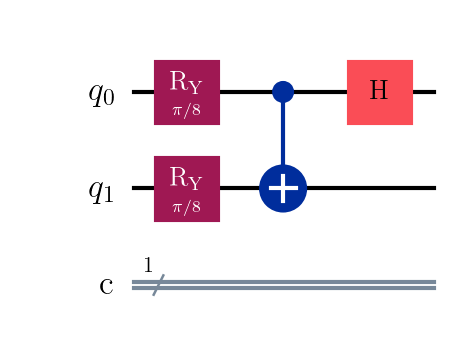

In [25]:
# Physical [[2,1,1]] circuit; qubit 0 is the output, qubit 1 is measured.
# NOTE: as saved this prepares RY(pi/8); the target-state lines are commented out.
qc = QuantumCircuit(2,1)

# State preparation
qc.ry(np.pi/8, 0)
qc.ry(np.pi/8, 1)
#qc.ry(theta,0)
#qc.ry(theta,1)

# Distillation circuit
qc.cx(0,1)
qc.h(0)

display(qc.draw(output='mpl'))

# Infidelity to Error Rates

In [6]:
# Output "error rate" = depolarizing-equivalent parameter: lambda = r * d/(d-1)
# for an average infidelity r on d = 2^num_qubits levels (Qiskit's
# depolarizing_error(lambda) has average infidelity lambda (d-1)/d). For one
# qubit, error rate = 2 * infidelity. Gate infidelities go through the same map.
def inf_to_error(infidelity_list, num_qubits, infidelity_uncertainty_list=None):
    if infidelity_uncertainty_list is None:
        error_rates_list = []
        dimension = 2**num_qubits
        for infidelity in infidelity_list:
            error_rates_list.append( infidelity * (dimension / (dimension - 1)) )
        
        return error_rates_list
    else:
        error_rates_list = []
        error_uncertainty_list = []

        dimension = 2**num_qubits
        scale = dimension / (dimension - 1)

        for infidelity, uncertainty in zip(infidelity_list, infidelity_uncertainty_list):
            error_rates_list.append(scale * infidelity)
            error_uncertainty_list.append(scale * uncertainty)

        return error_rates_list, error_uncertainty_list

In [7]:
# Quantinuum H2-2 infidelities scaled by 1x..5x (five points per sweep):
# one-qubit gate, two-qubit gate, idle, and readout P(1|0) (spam0) / P(0|1) (spam1).
one_qubit_gate_infidelity = [2.8e-5 * i for i in range(1,6)]
two_qubit_gate_infidelity = [8.3e-4 * i for i in range(1,6)]
idle_gate_infidelity = [1.2e-4 * i for i in range(1,6)]
spam0 = [6.7e-4 * i for i in range(1,6)] # P(1|0), measured 1 given that 0 was prepared
spam1 = [1.2e-3 * i for i in range(1,6)] # P(0|1)

In [8]:
one_qubit_gate_error_prob = inf_to_error(one_qubit_gate_infidelity, num_qubits=1)
two_qubit_gate_error_prob = inf_to_error(two_qubit_gate_infidelity, num_qubits=2)
idle_gate_error_prob = inf_to_error(idle_gate_infidelity, num_qubits=1)

# Threshold Simulations

In [26]:
input_error_rate_list = np.linspace(0.0005,0.4, 500)

Consider the case when only state preparation is noisy

In [27]:
ideal = QuantumCircuit(2)
ideal.ry(theta,0)
ideal_dm = DensityMatrix(ideal)

In [28]:
# Post-selection: with conditional=True, Aer saves the state under the hex key
# of the classical register; '0x0' = measured qubit(s) read 0 (accepted branch).
# The density_matrix method stores the exact conditional state, so the first
# entry is used; shots only needs to be large enough to sample outcome 0.
fid_list_noisy_prep = []
shots = 50

for i in range(len(input_error_rate_list)):
    noise_model = NoiseModel()
    # Add depolarizing noise to state preparation gate. 
    noise_model.add_all_qubit_quantum_error(
        depolarizing_error(input_error_rate_list[i], 1),
        ['ry']
    )
    
    # Measure for post-selection and save the conditional density matrix.
    meas_circuit = qc.copy()
    meas_circuit.measure([1], [0])
    meas_circuit.append(
        SaveDensityMatrix(
            num_qubits=2,
            label='dm_post',
            conditional=True,
            pershot=True
        ),
        meas_circuit.qubits
    )
    
    # Run the noisy simulation.
    backend = AerSimulator(noise_model=noise_model, method='density_matrix')
    job = backend.run(meas_circuit, shots=shots)
    result = job.result()

    # Keep a post-selected run with measurement outcome 0, and compute its fidelity.
    res_dm = result.data()['dm_post']
    temp_fid = state_fidelity(ideal_dm, res_dm['0x0'][0])
    fid_list_noisy_prep.append(temp_fid)

infid_list_noisy_prep = [1-f for f in fid_list_noisy_prep]

In [29]:
# NOTE: the crossing search below is disabled (inside a string), so on a
# fresh run x_intersect is undefined; the printed/saved value is from an earlier run.
# Finding the intersection of the curve with y=x
output_error_rate = inf_to_error(infid_list_noisy_prep, 1)
y = output_error_rate
x = input_error_rate_list
"""
diff = y - x

# Find where the sign changes
idx = np.where(diff[:-1] * diff[1:] <= 0)[0][0]

# Interpolate intersection in log-log space
logx1, logx2 = np.log(x[idx]), np.log(x[idx + 1])
logy1, logy2 = np.log(y[idx]), np.log(y[idx + 1])

# Interpolate log(output/input)
f1 = logy1 - logx1
f2 = logy2 - logx2

logx_intersect = logx1 - f1 * (logx2 - logx1) / (f2 - f1)
x_intersect = np.exp(logx_intersect)
y_intersect = x_intersect
"""

'\ndiff = y - x\n\n# Find where the sign changes\nidx = np.where(diff[:-1] * diff[1:] <= 0)[0][0]\n\n# Interpolate intersection in log-log space\nlogx1, logx2 = np.log(x[idx]), np.log(x[idx + 1])\nlogy1, logy2 = np.log(y[idx]), np.log(y[idx + 1])\n\n# Interpolate log(output/input)\nf1 = logy1 - logx1\nf2 = logy2 - logx2\n\nlogx_intersect = logx1 - f1 * (logx2 - logx1) / (f2 - f1)\nx_intersect = np.exp(logx_intersect)\ny_intersect = x_intersect\n'

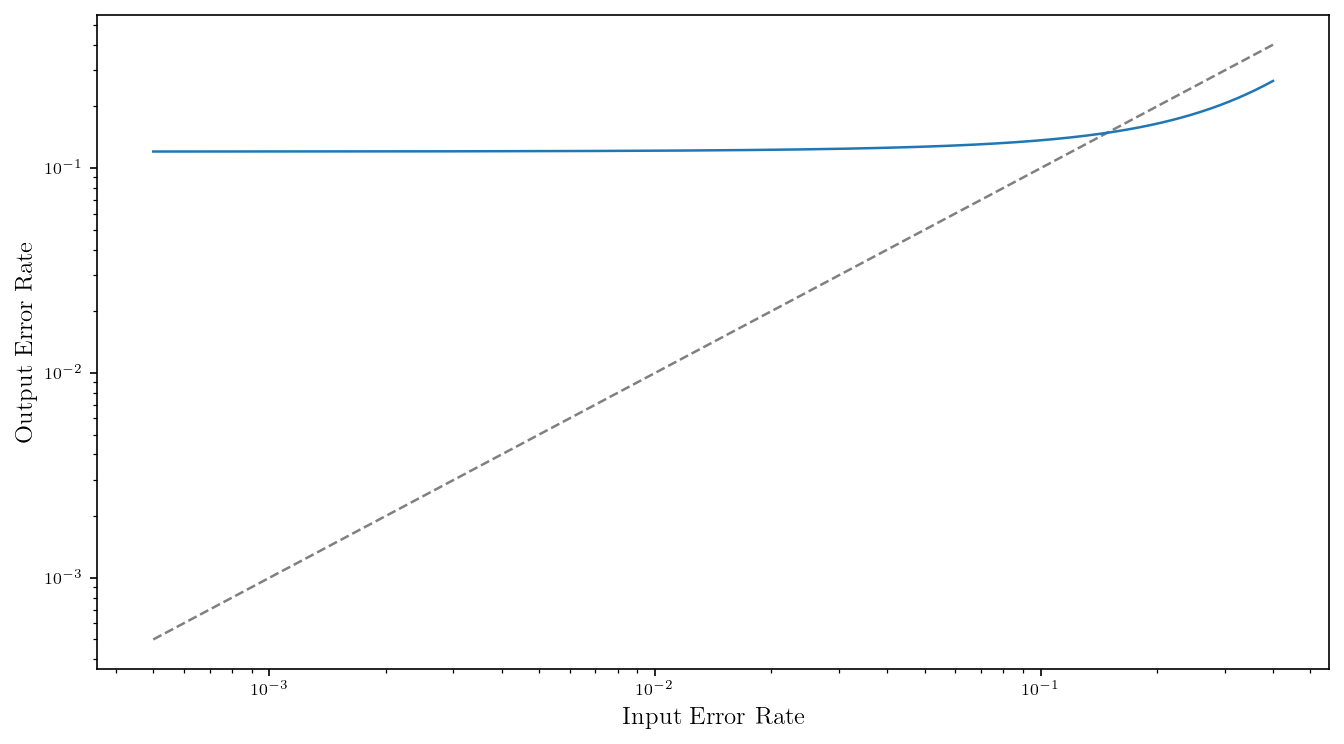

In [30]:
plt.figure(figsize=(9, 5))

plt.plot(input_error_rate_list, input_error_rate_list, color="gray", linestyle="--")
plt.plot(input_error_rate_list, output_error_rate)
#plt.scatter(x_intersect, y_intersect, color="green", s=40, zorder=5,)
plt.xlabel("Input Error Rate", fontsize=12)
plt.ylabel("Output Error Rate", fontsize=12)
plt.yscale('log')
plt.xscale('log')
plt.tight_layout()
plt.show()

In [14]:
print(x_intersect)

0.7044023647315808


# Error Contribution Simulations

Ideal output

In [15]:
ideal = QuantumCircuit(2)
ideal.ry(theta,0)
ideal_dm = DensityMatrix(ideal)

In [16]:
ideal_infidelity_list = []
shots = 50

for i in range(len(one_qubit_gate_error_prob)):
    noise_model = NoiseModel()
    # Add depolarizing noise to state preparation gate. 
    noise_model.add_all_qubit_quantum_error(
        depolarizing_error(one_qubit_gate_error_prob[i], 1),
        ['ry']
    )
    
    # Measure for post-selection and save the conditional density matrix.
    meas_circuit = qc.copy()
    meas_circuit.measure([1], [0])
    meas_circuit.append(
        SaveDensityMatrix(
            num_qubits=2,
            label='dm_post',
            conditional=True,
            pershot=True
        ),
        meas_circuit.qubits
    )
    
    # Run the noisy simulation.
    backend = AerSimulator(noise_model=noise_model, method='density_matrix')
    job = backend.run(meas_circuit, shots=shots)
    result = job.result()

    # Keep a post-selected run with measurement outcome 0, and compute its fidelity.
    res_dm = result.data()['dm_post']
    temp_fid = state_fidelity(ideal_dm, res_dm['0x0'][0])
    ideal_infidelity_list.append(1-temp_fid)

ideal_output_error_rate = inf_to_error(ideal_infidelity_list, 1)

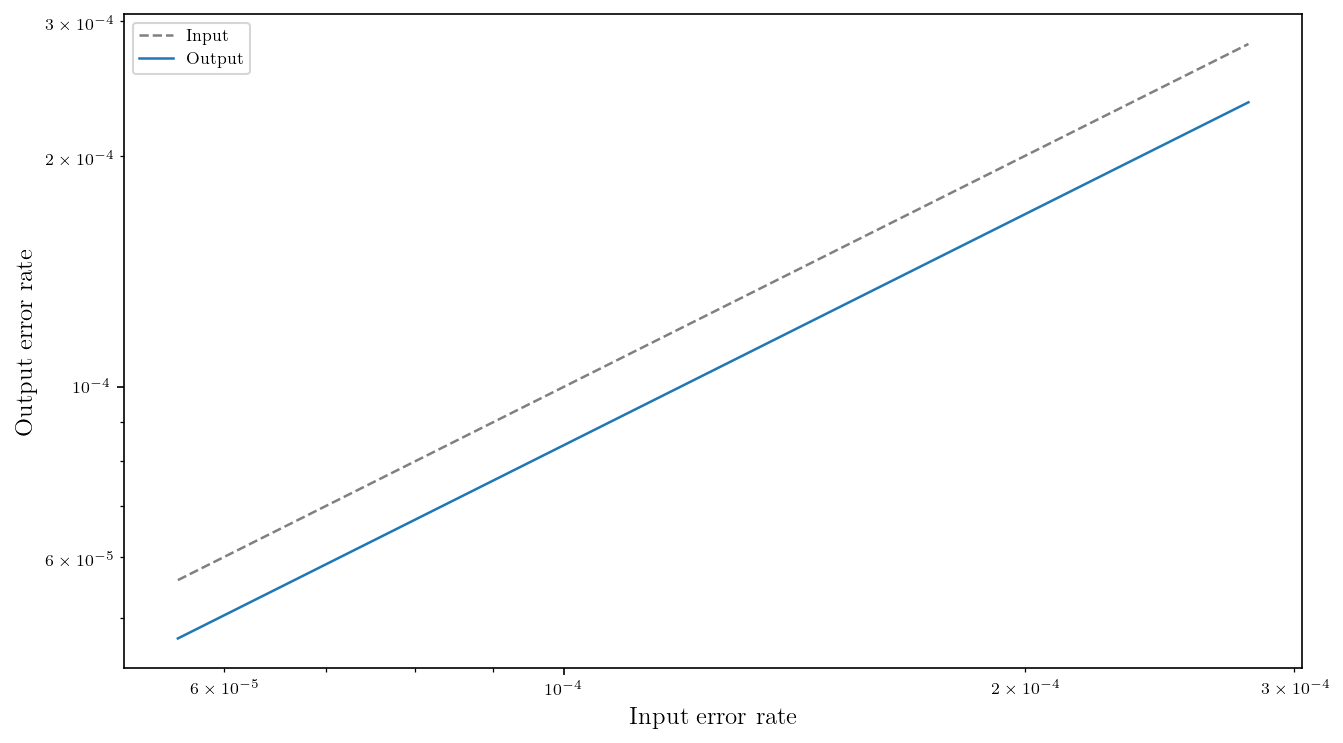

In [23]:
plt.figure(figsize=(9, 5))

plt.plot(one_qubit_gate_error_prob, one_qubit_gate_error_prob, color="gray", linestyle="--", label="Input")
plt.plot(one_qubit_gate_error_prob, ideal_output_error_rate, label="Output")
plt.xlabel("Input error rate", fontsize=12)
plt.ylabel("Output error rate", fontsize=12)
plt.yscale('log')
plt.xscale('log')
plt.tight_layout()
plt.legend()
plt.show()

Only cx errors

In [18]:
cx_infidelity_list = []
shots = 50

for i in range(len(one_qubit_gate_error_prob)):
    noise_model = NoiseModel()
    # Add depolarizing noise to state preparation gate. 
    noise_model.add_all_qubit_quantum_error(
        depolarizing_error(one_qubit_gate_error_prob[i], 1),
        ['ry']
    )
    noise_model.add_all_qubit_quantum_error(
        depolarizing_error(two_qubit_gate_error_prob[i], 2),
        ['cx']
    )
    
    # Measure for post-selection and save the conditional density matrix.
    meas_circuit = qc.copy()
    meas_circuit.measure([1], [0])
    meas_circuit.append(
        SaveDensityMatrix(
            num_qubits=2,
            label='dm_post',
            conditional=True,
            pershot=True
        ),
        meas_circuit.qubits
    )
    
    # Run the noisy simulation.
    backend = AerSimulator(noise_model=noise_model, method='density_matrix')
    job = backend.run(meas_circuit, shots=shots)
    result = job.result()

    # Keep a post-selected run with measurement outcome 0, and compute its fidelity.
    res_dm = result.data()['dm_post']
    temp_fid = state_fidelity(ideal_dm, res_dm['0x0'][0])
    cx_infidelity_list.append(1-temp_fid)

cx_output_error_rate = inf_to_error(cx_infidelity_list, 1)

Only H errors

In [19]:
h_infidelity_list = []
shots = 50

for i in range(len(one_qubit_gate_error_prob)):
    noise_model = NoiseModel()
    # Add depolarizing noise to state preparation gate. 
    noise_model.add_all_qubit_quantum_error(
        depolarizing_error(one_qubit_gate_error_prob[i], 1),
        ['ry']
    )
    noise_model.add_all_qubit_quantum_error(
        depolarizing_error(one_qubit_gate_error_prob[i], 1),
        ['h']
    )
    
    # Measure for post-selection and save the conditional density matrix.
    meas_circuit = qc.copy()
    meas_circuit.measure([1], [0])
    meas_circuit.append(
        SaveDensityMatrix(
            num_qubits=2,
            label='dm_post',
            conditional=True,
            pershot=True
        ),
        meas_circuit.qubits
    )
    
    # Run the noisy simulation.
    backend = AerSimulator(noise_model=noise_model, method='density_matrix')
    job = backend.run(meas_circuit, shots=shots)
    result = job.result()

    # Keep a post-selected run with measurement outcome 0, and compute its fidelity.
    res_dm = result.data()['dm_post']
    temp_fid = state_fidelity(ideal_dm, res_dm['0x0'][0])
    h_infidelity_list.append(1-temp_fid)

h_output_error_rate = inf_to_error(h_infidelity_list, 1)

Only measurement errors

In [20]:
# Statevector sampling: each accepted shot ('0x0') is one pure-state trajectory,
# so F is averaged over accepted shots. Uncertainty = 1.96*sqrt(F(1-F)/N)
# (95% normal approximation, N = accepted shots).
meas_infidelity_list = []
meas_infidelity_list_unc = []
shots = 1_000_000
ncpus = os.cpu_count()

for i in range(len(one_qubit_gate_error_prob)):
    noise_model = NoiseModel()
    # Add depolarizing noise to state preparation gate. 
    noise_model.add_all_qubit_quantum_error(
        depolarizing_error(one_qubit_gate_error_prob[i], 1),
        ['ry']
    )
    
    # Add readout errors on the measured qubits.
    readout_err = ReadoutError([
        [1 - spam0[i], spam0[i]],
        [spam1[i], 1 - spam1[i]]
    ])
    noise_model.add_readout_error(readout_err, [1])
    
    # Measure for post-selection and save the conditional density matrix.
    meas_circuit = qc.copy()
    meas_circuit.measure([1], [0])
    meas_circuit.append(
        SaveStatevector(
            num_qubits=2,
            label='sv_post',
            conditional=True,
            pershot=True
        ),
        meas_circuit.qubits
    )
    
    # Run the noisy simulation.
    backend = AerSimulator(noise_model=noise_model, method='statevector', max_parallel_threads=ncpus)
    job = backend.run(meas_circuit, shots=shots)
    result = job.result()

    # Keep a post-selected run with measurement outcome 0, and compute its fidelity.
    res_sv = result.data()['sv_post']
    accepted_sv = res_sv['0x0']
    num_meas = len(accepted_sv)
    
    # Average fidelity over accepted shots
    sumfid = 0
    for shot in accepted_sv:
        sumfid += state_fidelity(ideal_dm, shot)
        
    sumfid /= num_meas
    meas_infidelity_list.append(1-sumfid)
    
    meas_infidelity_list_unc.append(
        1.96 * np.sqrt(sumfid * (1 - sumfid) / num_meas)
    )
    
meas_output_error_rate, meas_output_error_rate_unc = inf_to_error(meas_infidelity_list, 1, meas_infidelity_list_unc)

All errors

In [22]:
all_infidelity_list = []
all_infidelity_list_unc = []
shots = 1_000_000
ncpus = os.cpu_count()

for i in range(len(one_qubit_gate_error_prob)):
    noise_model = NoiseModel()
    # Add depolarizing noise to state preparation gate. 
    noise_model.add_all_qubit_quantum_error(
        depolarizing_error(one_qubit_gate_error_prob[i], 1),
        ['ry']
    )
    noise_model.add_all_qubit_quantum_error(
        depolarizing_error(one_qubit_gate_error_prob[i], 1),
        ['h']
    )
    noise_model.add_all_qubit_quantum_error(
        depolarizing_error(two_qubit_gate_error_prob[i], 2),
        ['cx']
    )
    
    # Add readout errors on the measured qubits.
    readout_err = ReadoutError([
        [1 - spam0[i], spam0[i]],
        [spam1[i], 1 - spam1[i]]
    ])
    noise_model.add_readout_error(readout_err, [1])
    
    # Measure for post-selection and save the conditional density matrix.
    meas_circuit = qc.copy()
    meas_circuit.measure([1], [0])
    meas_circuit.append(
        SaveStatevector(
            num_qubits=2,
            label='sv_post',
            conditional=True,
            pershot=True
        ),
        meas_circuit.qubits
    )
    
    # Run the noisy simulation.
    backend = AerSimulator(noise_model=noise_model, method='statevector', max_parallel_threads=ncpus)
    job = backend.run(meas_circuit, shots=shots)
    result = job.result()

    # Keep a post-selected run with measurement outcome 0, and compute its fidelity.
    res_sv = result.data()['sv_post']
    accepted_sv = res_sv['0x0']
    num_meas = len(accepted_sv)
    
    # Average fidelity over accepted shots
    sumfid = 0
    for shot in accepted_sv:
        sumfid += state_fidelity(ideal_dm, shot)
        
    sumfid /= num_meas
    all_infidelity_list.append(1-sumfid)
    
    all_infidelity_list_unc.append(
        1.96 * np.sqrt(sumfid * (1 - sumfid) / num_meas)
    )
    
all_output_error_rate, all_output_error_rate_unc = inf_to_error(all_infidelity_list, 1, all_infidelity_list_unc)

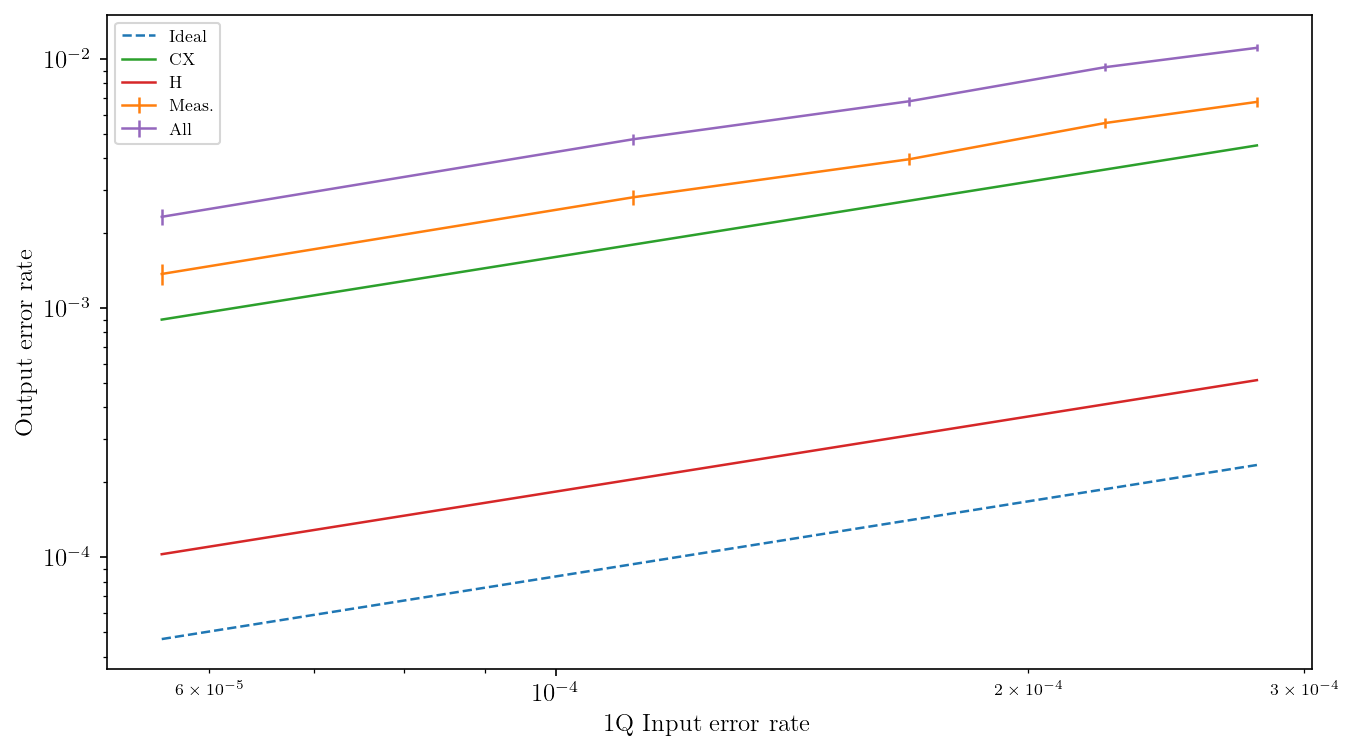

In [24]:
# Every plot without input and ideal circuit
plt.figure(figsize=(9,5))

plt.plot(one_qubit_gate_error_prob, ideal_output_error_rate, linestyle=f'--', label='Ideal')
plt.errorbar(one_qubit_gate_error_prob, meas_output_error_rate, yerr=meas_output_error_rate_unc, label='Meas.')
plt.plot(one_qubit_gate_error_prob, cx_output_error_rate, label='CX')
plt.plot(one_qubit_gate_error_prob, h_output_error_rate, label='H')
plt.errorbar(one_qubit_gate_error_prob, all_output_error_rate, yerr=all_output_error_rate_unc, label='All')

plt.xscale('log')
plt.yscale('log')

plt.legend()
plt.ylabel('Output error rate', fontsize=12)
plt.xlabel('1Q Input error rate', fontsize=12)
plt.tight_layout()
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()

Calculating error contributions

In [25]:
# Error budget: at each of the five rates take each component's output error
# rate as a fraction of (H or 1Q) + (CX/CZ or 2Q) + Meas, then average the
# fractions over the rates. Each component run also includes the input-state noise.
sum_c_list = []
for i in range(len(one_qubit_gate_error_prob)):
    sum_c_list.append(h_output_error_rate[i] + cx_output_error_rate[i] + meas_output_error_rate[i])

hadamard_contributions = 0
cx_contributions = 0
measurement_contributions = 0
for i in range(len(one_qubit_gate_error_prob)):
    hadamard_contributions += h_output_error_rate[i] / sum_c_list[i]
    cx_contributions += cx_output_error_rate[i] / sum_c_list[i]
    measurement_contributions += meas_output_error_rate[i] / sum_c_list[i]

hadamard_contributions /= len(one_qubit_gate_error_prob)
cx_contributions /= len(one_qubit_gate_error_prob)
measurement_contributions /= len(one_qubit_gate_error_prob)

# Saving Data

In [62]:
# Writes the file used by the plotting notebooks and as the 'Optimal'
# curve in notebooks/two_qubit/logical_level/depolarizing.ipynb.
np.savez(
    "../../../../data/two_qubit/physical_level/one_round/depolarizing_error_rates.npz",
    input_error_rate_list=input_error_rate_list,
    output_error_rate=output_error_rate,
    intersection=x_intersect,
    ideal_output_error_rate=ideal_output_error_rate,
    cx_output_error_rate=cx_output_error_rate,
    h_output_error_rate=h_output_error_rate,
    meas_output_error_rate=meas_output_error_rate,
    meas_output_error_rate_unc=meas_output_error_rate_unc,
    all_output_error_rate=all_output_error_rate,
    all_output_error_rate_unc=all_output_error_rate_unc,
    hadamard_contributions=hadamard_contributions,
    cx_contributions=cx_contributions,
    measurement_contributions=measurement_contributions,
    one_qubit_gate_error_prob=one_qubit_gate_error_prob
)

# Loading Data

In [67]:
data = np.load("../../../../data/two_qubit/physical_level/one_round/depolarizing_error_rates.npz")

input_error_rate_list = data["input_error_rate_list"]
output_error_rate = data["output_error_rate"]
intersection = data["intersection"]
ideal_output_error_rate = data["ideal_output_error_rate"]
cx_output_error_rate = data["cx_output_error_rate"]
h_output_error_rate = data["h_output_error_rate"]
meas_output_error_rate = data["meas_output_error_rate"]
meas_output_error_rate_unc = data["meas_output_error_rate_unc"]
all_output_error_rate = data["all_output_error_rate"]
all_output_error_rate_unc = data["all_output_error_rate_unc"]
hadamard_contributions = data["hadamard_contributions"]
cx_contributions = data["cx_contributions"]
measurement_contributions = data["measurement_contributions"]
one_qubit_gate_error_prob = data["one_qubit_gate_error_prob"]